In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [2]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical = [
    'lead_source',
    'industry',
    'employment_status',
    'location'
]

numerical = [
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score'
]

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [5]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [6]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

print("Train:", df_train.shape)
print("Validation:", df_val.shape)
print("Test:", df_test.shape)

Train: (3000, 9)
Validation: (1000, 9)
Test: (1000, 9)


In [7]:
from sklearn.metrics import roc_auc_score

In [8]:
y_train = df_train['converted'].values

for feature in numerical:
    auc = roc_auc_score(y_train, df_train[feature])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])

    print(f'{feature}: {auc:.4f}')

annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882


In [9]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [10]:
features = categorical + numerical

train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

y_train = df_train['converted'].values
y_val = df_val['converted'].values

In [11]:
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)

Training matrix: (3000, 28)
Validation matrix: (1000, 28)


In [12]:
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [13]:
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print(f"Validation AUC: {auc:.3f}")

Validation AUC: 0.732


In [14]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.01, 0.01)

scores = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    precision = precision_score(
        y_val, y_pred_binary, zero_division=0
    )

    recall = recall_score(
        y_val, y_pred_binary, zero_division=0
    )

    scores.append((t, precision, recall))

df_scores = pd.DataFrame(
    scores,
    columns=['threshold', 'precision', 'recall']
)

df_scores.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


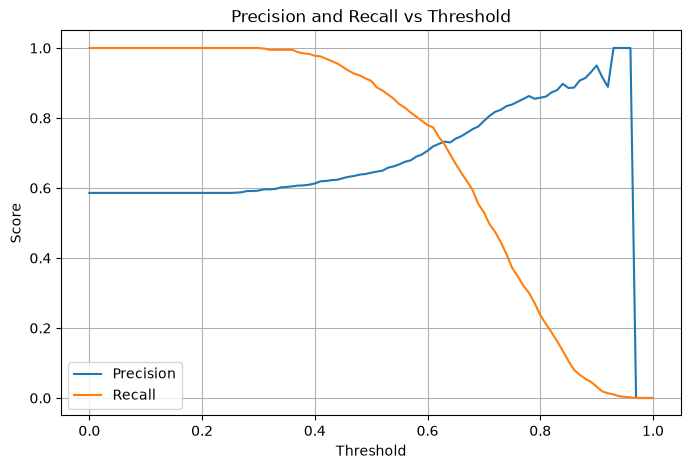

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    df_scores.threshold,
    df_scores.precision,
    label='Precision'
)

plt.plot(
    df_scores.threshold,
    df_scores.recall,
    label='Recall'
)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid()
plt.show()

In [16]:
df_nonzero = df_scores[
    ~(
        (df_scores.precision == 0) &
        (df_scores.recall == 0)
    )
].copy()

df_nonzero['difference'] = abs(
    df_nonzero.precision - df_nonzero.recall
)

best_row = df_nonzero.loc[
    df_nonzero.difference.idxmin()
]

print(f"Best threshold: {best_row['threshold']:.2f}")
print(f"Precision: {best_row['precision']:.4f}")
print(f"Recall: {best_row['recall']:.4f}")
print(f"Absolute difference: {best_row['difference']:.6f}")

Best threshold: 0.63
Precision: 0.7328
Recall: 0.7253
Absolute difference: 0.007503


In [17]:
df_scores['f1'] = (
    2 * df_scores.precision * df_scores.recall /
    (df_scores.precision + df_scores.recall)
)

df_scores['f1'] = df_scores['f1'].fillna(0)

df_scores.head()

,threshold,precision,recall,f1
0,0.00,0.586,1.0,0.738966
1,0.01,0.586,1.0,0.738966
2,0.02,0.586,1.0,0.738966
3,0.03,0.586,1.0,0.738966
4,0.04,0.586,1.0,0.738966


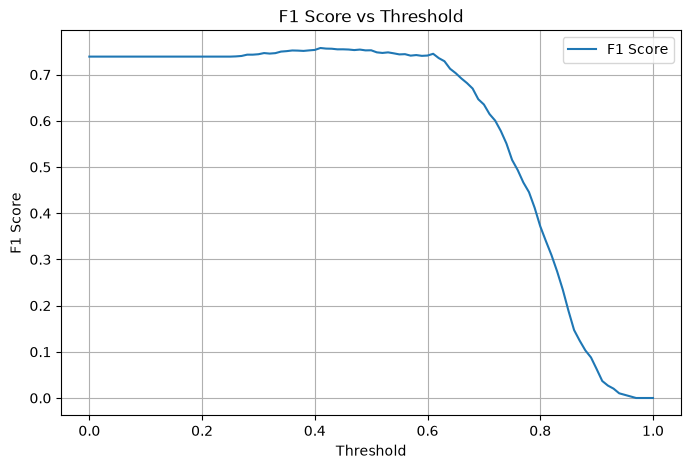

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_scores.threshold,
    df_scores.f1,
    label='F1 Score'
)

plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.grid()
plt.legend()
plt.show()

In [19]:
best_f1_row = df_scores.loc[df_scores.f1.idxmax()]

print(f"Best threshold: {best_f1_row['threshold']:.2f}")
print(f"Maximum F1: {best_f1_row['f1']:.4f}")
print(f"Precision: {best_f1_row['precision']:.4f}")
print(f"Recall: {best_f1_row['recall']:.4f}")

Best threshold: 0.41
Maximum F1: 0.7576
Precision: 0.6190
Recall: 0.9761


In [20]:
from sklearn.model_selection import KFold

In [21]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

auc_scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    y_train_fold = df_train_fold['converted'].values
    y_val_fold = df_val_fold['converted'].values

    train_dicts = df_train_fold[features].to_dict(orient='records')
    val_dicts = df_val_fold[features].to_dict(orient='records')

    dv_fold = DictVectorizer(sparse=False)

    X_train_fold = dv_fold.fit_transform(train_dicts)
    X_val_fold = dv_fold.transform(val_dicts)

    model_fold = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model_fold.fit(X_train_fold, y_train_fold)

    y_pred_fold = model_fold.predict_proba(X_val_fold)[:, 1]

    auc = roc_auc_score(y_val_fold, y_pred_fold)
    auc_scores.append(auc)

print("AUC scores:", np.round(auc_scores, 4))

AUC scores: [0.7306 0.7296 0.7363 0.7412 0.7209]


In [22]:
mean_auc = np.mean(auc_scores)
std_auc = np.std(auc_scores)

print(f"Mean AUC: {mean_auc:.4f}")
print(f"Standard deviation: {std_auc:.4f}")
print(f"Standard deviation (3 decimals): {std_auc:.3f}")

Mean AUC: 0.7317
Standard deviation: 0.0069
Standard deviation (3 decimals): 0.007


In [23]:
from sklearn.model_selection import KFold

C_values = [0.000001, 0.001, 1]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

results = []

for C in C_values:
    auc_scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        y_train_fold = df_train_fold['converted'].values
        y_val_fold = df_val_fold['converted'].values

        train_dicts = df_train_fold[features].to_dict(orient='records')
        val_dicts = df_val_fold[features].to_dict(orient='records')

        dv_fold = DictVectorizer(sparse=False)

        X_train_fold = dv_fold.fit_transform(train_dicts)
        X_val_fold = dv_fold.transform(val_dicts)

        model_fold = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model_fold.fit(X_train_fold, y_train_fold)

        y_pred_fold = model_fold.predict_proba(X_val_fold)[:, 1]

        auc = roc_auc_score(y_val_fold, y_pred_fold)
        auc_scores.append(auc)

    mean_auc = np.mean(auc_scores)
    std_auc = np.std(auc_scores)

    results.append((C, round(mean_auc, 3), round(std_auc, 3)))

    print(f"C={C:<10} Mean AUC={mean_auc:.3f} Std={std_auc:.3f}")

C=1e-06      Mean AUC=0.617 Std=0.019
C=0.001      Mean AUC=0.749 Std=0.010
C=1          Mean AUC=0.732 Std=0.007


In [24]:
df_results = pd.DataFrame(
    results,
    columns=['C', 'mean_auc', 'std_auc']
)

df_results

,C,mean_auc,std_auc
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007


In [25]:
best_result = df_results.sort_values(
    by=['mean_auc', 'std_auc', 'C'],
    ascending=[False, True, True]
).iloc[0]

print(f"Best C: {best_result['C']:.6f}")
print(f"Mean AUC: {best_result['mean_auc']:.3f}")
print(f"Std AUC: {best_result['std_auc']:.3f}")

Best C: 0.001000
Mean AUC: 0.749
Std AUC: 0.010
